# Particle Filter Debug Graphs
Uses collected data from a particle filter run to visualize what could be wrong.

In [1]:
%matplotlib inline

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from vis_loc.field import Field
from vis_loc.localize import Localize

field = Field()
loc = Localize(100, 80)

csv_path = "logs/particle_log_20261009_185441.csv"
df = pd.read_csv(csv_path)

if df.empty:
    print(f"No data found in {csv_path}")
else:
    steps = sorted(df["step"].unique())
    n_steps = len(steps)
    cols = 6
    rows = int(np.ceil(n_steps / cols))

    fig, axes = plt.subplots(rows, cols, figsize=(5 * cols, 4 * rows), sharex=True, sharey=True)
    axes = axes.flatten() if n_steps > 1 else [axes]

    for ax, step in zip(axes, steps):
        step_df = df[df["step"] == step]
        ax.scatter(step_df["error"], step_df["weight"], s=12, alpha=0.7) # type: ignore
        ax.set_title(f"Step {step}") # type: ignore
        ax.set_xlabel("Error") # type: ignore
        ax.set_ylabel("Weight") # type: ignore
        ax.grid(True, alpha=0.5) # type: ignore

    for ax in axes[n_steps:]:
        ax.axis("off") # type: ignore

    fig.suptitle("Weight vs Error by Step", y=1)
    fig.tight_layout()
    display(fig)
    plt.close(fig)

FileNotFoundError: [Errno 2] No such file or directory: 'logs/particle_log_20261009_185441.csv'

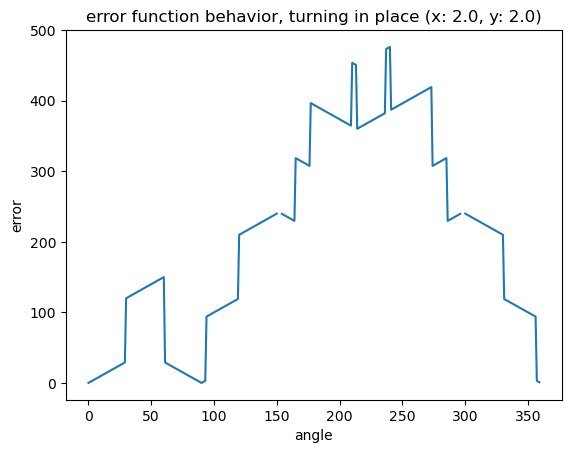

In [ ]:
# error function debug
from vis_loc.field import Field
from vis_loc.localize import Localize
import matplotlib.pyplot as plt

field = Field()
loc = Localize(200, 90)

def err_360():
    angle = []
    fn_out = []

    coords = (2.0, 2.0) # x, y

    for i in range(360):
        obs = field.predicted_output((coords[0], coords[1], 0), 120, 12)
        p = field.predicted_output((coords[0], coords[1], i), 120, 12)
        error = loc.calc_error(p, obs)
        fn_out.append(error) 
        angle.append(i)

    # debug plotting
    plt.plot(angle, fn_out)

    plt.xlabel('angle')
    plt.ylabel('error')
    plt.title('error function behavior, turning in place (x: 2.0, y: 2.0)')

err_360()


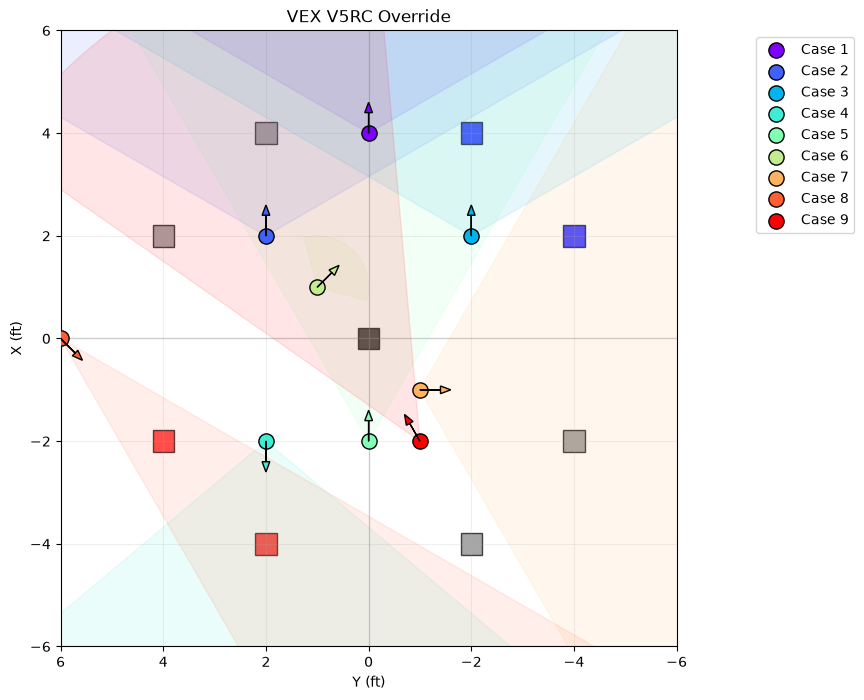

Case 1: Robot is at (4.0, 0.0) looking at 0°
robot sees: []
Case 2: Robot is at (2.0, 2.0) looking at 0°
robot sees: [(3, np.float64(0.0))]
Case 3: Robot is at (2.0, -2.0) looking at 0°
robot sees: [(2, np.float64(0.0))]
Case 4: Robot is at (-2.0, 2.0) looking at 180°
robot sees: [(1, np.float64(0.0))]
Case 5: Robot is at (-2.0, 0.0) looking at 0°
robot sees: [(0, np.float64(0.0)), (3, np.float64(18.434948822922024)), (2, np.float64(-18.434948822922024))]
Case 6: Robot is at (1.0, 1.0) looking at -45°
robot sees: []
Case 7: Robot is at (-1.0, -1.0) looking at -90°
robot sees: [(3, np.float64(-18.434948822922024)), (2, np.float64(45.0))]
Case 8: Robot is at (0.0, 6.0) looking at -135°
robot sees: [(1, np.float64(0.0))]
Case 9: Robot is at (-2.0, -1.0) looking at 30°
robot sees: [(0, np.float64(-3.434948822922024)), (3, np.float64(21.34019174590992))]


In [2]:
%matplotlib inline

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Wedge

from vis_loc.field import Field


def plot_robotics_test_poses(field, test_cases):

    fig, ax = field.plot_base()
    
    colors = plt.cm.rainbow(np.linspace(0, 1, len(test_cases)))
    
    for idx, (pose, fov, range_val, _) in enumerate(test_cases):
        px, py, heading = pose
        color = colors[idx]
        heading_rad = np.radians(heading)
        
        ax.scatter(py, px, color=color, s=120, zorder=5, edgecolors='black', label=f"Case {idx+1}")
        
        ax.arrow(
            x=py, y=px, 
            dx=np.sin(heading_rad) * 0.4,  
            dy=np.cos(heading_rad) * 0.4, 
            head_width=0.15, head_length=0.2, fc=color, ec='black', zorder=6
        )
        
     
        if range_val > 0:

            theta1 = 90 - heading - (fov / 2)
            theta2 = 90 - heading + (fov / 2)
            
            fov_wedge = Wedge(
                center=(py, px), r=range_val, 
                theta1=theta1, theta2=theta2, 
                color=color, alpha=0.1, zorder=2
            )
            ax.add_patch(fov_wedge)
            
    ax.legend(loc='upper right', bbox_to_anchor=(1.3, 1))
    return fig, ax


test_cases = [
    ((4.0, 0.0, 0), 120, 12, []), # case 1
    ((2.0, 2.0, 0), 120, 12, [(3, 0)]),  # case 2
    ((2.0, -2.0, 0), 120, 12, [(2, 0)]),  # case 3
    ((-2.0, 2.0, 180), 100, 12, [(1, 0)]), # case 4
    ((-2.0, 0.0, 0), 60, 12, [(0, 0.0)]), # case 5
    ((1.0, 1.0, -45), 120, 1, []), # case 6
    ((-1.0, -1.0, -90), 120, 10, []), # case 7
    ((0.0, 6.0, -135), 30, 12, []), # case 8
    ((-2.0, -1.0, 30), 50, 10, [(3, 26.56), (3, -26.56)]) # case 9
]



field_instance = Field()
fig, ax = plot_robotics_test_poses(field_instance, test_cases)


plt.show()

for idx, (pose, fov, range_val, landmarks) in enumerate(test_cases):
    px, py, heading = pose
    obs = field_instance.predicted_output((px,py,heading), fov, range_val)
    print(f"Case {idx+1}: Robot is at ({px}, {py}) looking at {heading}°")
    print(f"robot sees: {obs}")


## Covariance

For `[x, y, yaw]`, the full ROS pose covariance matrix—ordered `[x, y, z, roll, pitch, yaw]`—is:

\[
\Sigma_{\text{ROS}}=
\begin{bmatrix}
\sigma_{xx} & \sigma_{xy} & 0 & 0 & 0 & \sigma_{x\psi}\\
\sigma_{xy} & \sigma_{yy} & 0 & 0 & 0 & \sigma_{y\psi}\\
0 & 0 & 0 & 0 & 0 & 0\\
0 & 0 & 0 & 0 & 0 & 0\\
0 & 0 & 0 & 0 & 0 & 0\\
\sigma_{x\psi} & \sigma_{y\psi} & 0 & 0 & 0 & \sigma_{\psi\psi}
\end{bmatrix},
\]

where \(\psi\) denotes yaw. In your matrix, the \(3\times3\) covariance for \([x,y,\psi]\) fills rows and columns \(0,1,5\) of the ROS matrix.